# Funktionen mehrerer Veränderlicher V: Tangentialebene und totales Differential

**Begleit-Notebook zum Vorlesungsskript „Angewandte Mathematik – 2. Funktionen mehrerer Veränderlicher“ (Abschnitt 2.6)**

Das Notebook folgt der Gliederung des Skripts. Definitionen, Sätze und Beispiele tragen dieselbe Nummer wie im Skript. Zu den Beispielen gibt es

* den Rechenweg aus dem Skript in Formeln,
* eine **Probe mit SymPy** (das Residuum muss 0 sein),
* eine **Grafik** und an einigen Stellen ein **interaktives Element** (Schieberegler),

**Voraussetzungen:** `numpy`, `sympy`, `matplotlib`, `ipywidgets`
**Arbeitsweise:** Zellen der Reihe nach ausführen und die Kontrollausgaben prüfen.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/karkessler/dhbw-mathe3/blob/main/notebooks/funktionen_mehrerer_veraenderlicher/05_tangentialebene_totales_differential.ipynb)

**Inhalt**


1. Definition 2.6.1: Tangentialebene als lineare Näherung
2. Beispiel 2.6.2: Tangentialebene von $x^3y - xy^2 - 8y$ in $(1,1)$
3. Definition 2.6.3: totales (vollständiges) Differential
4. Beispiel 2.6.4: Näherung von $f(3.1,\,1.8)$ und der Fehler der Näherung
5. Anwendung: Fehlerfortpflanzung bei Messwerten


In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Markdown
from matplotlib import cm
plt.style.use('default')
plt.rcParams.update({
    'figure.figsize': (8, 4.5),
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
    'savefig.transparent': False,
    'axes.edgecolor': 'black',
    'axes.labelcolor': 'black',
    'axes.titlecolor': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black',
    'text.color': 'black',
    'axes.grid': True,
    'grid.color': '0.8',
    'legend.facecolor': 'white',
    'legend.edgecolor': '0.7',
})
sp.init_printing()

x, y, z = sp.symbols('x y z', real=True)
ROT, BLAU = '#d71920', '#0b5cad'


def pruefe(name, residuum):
    """Vereinfacht ein Residuum, gibt es aus und bricht ab, falls es nicht 0 ist."""
    r = sp.simplify(residuum)
    if isinstance(r, sp.MatrixBase):
        ok = all(sp.simplify(e) == 0 for e in r)
    else:
        ok = r == 0
    print(f'Probe {name}: Residuum = {r}  ->', 'ok' if ok else 'FEHLER')
    assert ok


def flaeche(f, xbereich, ybereich, n=60, ax=None, titel=None, cmap='YlOrBr_r', alpha=1.0, blick=(30, -60)):
    """Zeichnet z = f(x, y) als Fläche (f als NumPy-Funktion). Gibt die Achse zurück."""
    if ax is None:
        fig = plt.figure(figsize=(7, 5))
        ax = fig.add_subplot(projection='3d')
    X, Y = np.meshgrid(np.linspace(*xbereich, n), np.linspace(*ybereich, n))
    Z = f(X, Y)
    ax.plot_surface(X, Y, Z, cmap=cmap, alpha=alpha, linewidth=0.2, edgecolor=(0.3, 0.15, 0, 0.3),
                    rstride=max(1, n // 30), cstride=max(1, n // 30))
    ax.set(xlabel='x', ylabel='y', zlabel='z')
    ax.view_init(*blick)
    if titel:
        ax.set_title(titel)
    return ax


def hoehenlinien(f, xbereich, ybereich, n=300, ax=None, niveaus=12, titel=None, gefuellt=True):
    """Zeichnet die Höhenlinien f(x, y) = c (optional eingefärbt). Gibt die Achse zurück."""
    ax = ax or plt.gca()
    X, Y = np.meshgrid(np.linspace(*xbereich, n), np.linspace(*ybereich, n))
    Z = f(X, Y)
    if gefuellt:
        cf = ax.contourf(X, Y, Z, levels=niveaus, cmap='YlOrBr_r', extend='both')
        plt.colorbar(cf, ax=ax, shrink=0.85)
    cs = ax.contour(X, Y, Z, levels=niveaus, colors='0.25', linewidths=0.7)
    ax.clabel(cs, fontsize=7, fmt='%.2g')
    ax.set(xlabel='x', ylabel='y', aspect='equal')
    if titel:
        ax.set_title(titel)
    return ax

## 1. Definition 2.6.1: Tangentialebene

So wie die Tangente im Fall $n = 1$ für die Differenzierbarkeit einer Funktion steht, ist es im Fall $n > 1$ die **Tangentialebene**. Beide stehen für die **lineare Approximation** einer Funktion.

Ist $f:D\subseteq\mathbb{R}^m\to\mathbb{R}$ stetig differenzierbar ($f\in C^1(D)$) und $\tilde x\in D$, so heißt die lineare Funktion
$$g(x_1,\dots,x_m) = f(\tilde x) + \frac{\partial f}{\partial x_1}(\tilde x)\,(x_1 - \tilde x_1) + \dots + \frac{\partial f}{\partial x_m}(\tilde x)\,(x_m - \tilde x_m) = f(\tilde x) + \nabla f(\tilde x)\cdot(x - \tilde x)$$
die **Tangentialebene** an $f$ im Punkt $\tilde x$. Für $m = 2$ ist ihr Graph eine Ebene, die die Fläche in $(\tilde x, f(\tilde x))$ berührt.

**Interaktiv:** Für $f(x,y) = x^2 + y^2$ lässt sich der Berührpunkt verschieben.

Output()

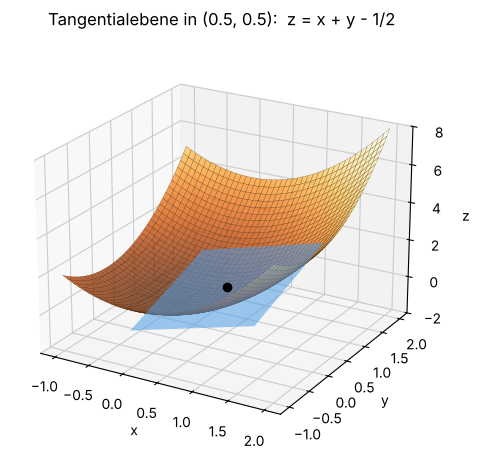

In [2]:
f_par = x**2 + y**2
fpn = sp.lambdify((x, y), f_par, 'numpy')


def tangentialebene(f, punkt):
    """Gibt die Tangentialebene g(x, y) von f im Punkt (x0, y0) als SymPy-Ausdruck zurück."""
    x0, y0 = punkt
    return sp.expand(f.subs({x: x0, y: y0}) + sp.diff(f, x).subs({x: x0, y: y0})*(x - x0)
                     + sp.diff(f, y).subs({x: x0, y: y0})*(y - y0))


def zeige_tangentialebene(x0=0.5, y0=0.5):
    g = tangentialebene(f_par, (sp.nsimplify(x0), sp.nsimplify(y0))); gn = sp.lambdify((x, y), g, 'numpy')
    fig = plt.figure(figsize=(8, 5.5))
    ax = fig.add_subplot(projection='3d', computed_zorder=False)
    flaeche(fpn, (-1, 2), (-1, 2), n=40, ax=ax, alpha=0.75)
    Xp, Yp = np.meshgrid(np.linspace(x0 - 0.9, x0 + 0.9, 2), np.linspace(y0 - 0.9, y0 + 0.9, 2))
    ax.plot_surface(Xp, Yp, gn(Xp, Yp) + 0*Xp, color='#4f9ee8', alpha=0.55, linewidth=0)
    ax.plot([x0], [y0], [fpn(x0, y0)], 'ko', zorder=20)
    ax.set(title=f'Tangentialebene in ({x0:.1f}, {y0:.1f}):  z = {g}', zlim=(-2, 8)); ax.view_init(22, -60)
    plt.show()


x0_r = widgets.FloatSlider(value=0.5, min=-0.8, max=1.8, step=0.1, description='x₀', continuous_update=False)
y0_r = widgets.FloatSlider(value=0.5, min=-0.8, max=1.8, step=0.1, description='y₀', continuous_update=False)
display(widgets.HBox([x0_r, y0_r]), widgets.interactive_output(zeige_tangentialebene, {'x0': x0_r, 'y0': y0_r}))

# Statische Vorschau für GitHub.
zeige_tangentialebene()

## 2. Beispiel 2.6.2

Bestimmen Sie die Tangentialebene von $f(x,y) = x^3y - xy^2 - 8y$ im Punkt $(1,1)$.

$$f_x(x,y) = 3x^2y - y^2\ \Rightarrow\ f_x(1,1) = 2,\qquad f_y(x,y) = x^3 - 2xy - 8\ \Rightarrow\ f_y(1,1) = -9,$$
und $f(1,1) = -8$. Damit lautet die Tangentialebene
$$g(x,y) = -8 + 2(x - 1) - 9(y - 1) = -1 + 2x - 9y.$$

Probe Skript-Ergebnis: Residuum = 0  -> ok
Probe Berührpunkt: f(1,1) = g(1,1): Residuum = 0  -> ok
Probe gleiche Steigungen: Residuum = Matrix([[0, 0]])  -> ok


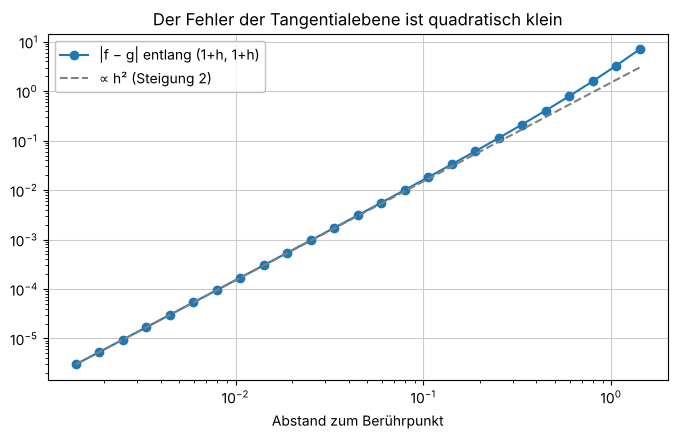

In [3]:
f262 = x**3*y - x*y**2 - 8*y
g262 = tangentialebene(f262, (1, 1))
display(sp.Eq(sp.Symbol('g(x,y)'), g262))
pruefe('Skript-Ergebnis', g262 - (-1 + 2*x - 9*y))
pruefe('Berührpunkt: f(1,1) = g(1,1)', (f262 - g262).subs({x: 1, y: 1}))
pruefe('gleiche Steigungen', sp.Matrix([f262 - g262]).jacobian([x, y]).subs({x: 1, y: 1}))

# Wie gut ist die Näherung? Abstand f - g wächst quadratisch mit dem Abstand zum Berührpunkt
fn, gn = sp.lambdify((x, y), f262, 'numpy'), sp.lambdify((x, y), g262, 'numpy')
hs = np.logspace(-3, 0, 25)
fehler = [abs(fn(1 + h, 1 + h) - gn(1 + h, 1 + h)) for h in hs]
plt.loglog(hs*np.sqrt(2), fehler, 'o-', label='|f − g| entlang (1+h, 1+h)')
plt.loglog(hs*np.sqrt(2), 3*hs**2, '--', color='0.5', label='∝ h² (Steigung 2)')
plt.xlabel('Abstand zum Berührpunkt'); plt.title('Der Fehler der Tangentialebene ist quadratisch klein'); plt.legend(); plt.show()

## 3. Definition 2.6.3: Totales Differential

Für $f\in C^1(D)$, $x_0\in D$ und **jedes** $a\in\mathbb{R}^m$ (hier nicht notwendig $\|a\| = 1$) gilt $\frac{\partial f}{\partial a}(x_0) = a\cdot\nabla f(x_0)$. Mit $a_i = dx_i$ (kleine Änderungen) erhält man das **vollständige (totale) Differential**
$$df = f_{x_1}\,dx_1 + f_{x_2}\,dx_2 + \dots + f_{x_m}\,dx_m.$$
Es beschreibt näherungsweise die Änderung von $f$, wenn sich **alle** Variablen **gleichzeitig** um $dx_1,\dots,dx_m$ ändern („vollständig“ im Sinne von „gleichzeitig“). Es ist genau der Zuwachs der Tangentialebene:
$$f(x_0 + dx)\approx f(x_0) + df.$$

## 4. Beispiel 2.6.4

Für $f(x_1,x_2) = x_1^2 + 3x_1x_2$ an der Stelle $x = (3,2)$:
$$f_{x_1} = 2x_1 + 3x_2\ \Rightarrow\ 12,\qquad f_{x_2} = 3x_1\ \Rightarrow\ 9,\qquad df = 12\,dx_1 + 9\,dx_2.$$
Näherung für $f(3.1,\,1.8)$, also $dx_1 = 0.1$, $dx_2 = -0.2$:
$$df = 12\cdot 0.1 + 9\cdot(-0.2) = -0.6,\qquad f(3.1,\,1.8)\approx f(3,2) + df = 27 - 0.6 = 26.4.$$
Der exakte Wert ist $f(3.1,\,1.8) = 26.35$.

In [4]:
x1, x2, dx1, dx2 = sp.symbols('x1 x2 dx1 dx2', real=True)
f264 = x1**2 + 3*x1*x2
df = sp.diff(f264, x1)*dx1 + sp.diff(f264, x2)*dx2
df_stelle = df.subs({x1: 3, x2: 2})
display(sp.Eq(sp.Symbol('df'), df_stelle))
pruefe('df an (3,2)', df_stelle - (12*dx1 + 9*dx2))
naeherung = f264.subs({x1: 3, x2: 2}) + df_stelle.subs({dx1: sp.Rational(1, 10), dx2: -sp.Rational(1, 5)})
exakt = f264.subs({x1: sp.Rational(31, 10), x2: sp.Rational(9, 5)})
print('Näherung:', float(naeherung), '  exakt:', float(exakt), '  Fehler:', float(exakt - naeherung))
print('Der Fehler ist genau der quadratische Anteil dx1² + 3 dx1 dx2 =', float(sp.Rational(1, 10)**2 + 3*sp.Rational(1, 10)*(-sp.Rational(1, 5))))

Probe df an (3,2): Residuum = 0  -> ok
Näherung: 26.4   exakt: 26.35   Fehler: -0.05
Der Fehler ist genau der quadratische Anteil dx1² + 3 dx1 dx2 = -0.05


**Interaktiv:** Wie gut ist die Näherung $f(3 + dx_1, 2 + dx_2)\approx 27 + 12\,dx_1 + 9\,dx_2$? Links der Fehler über einem Gitter von Änderungen, rechts der Wert für die eingestellten $dx_1, dx_2$.

Output()

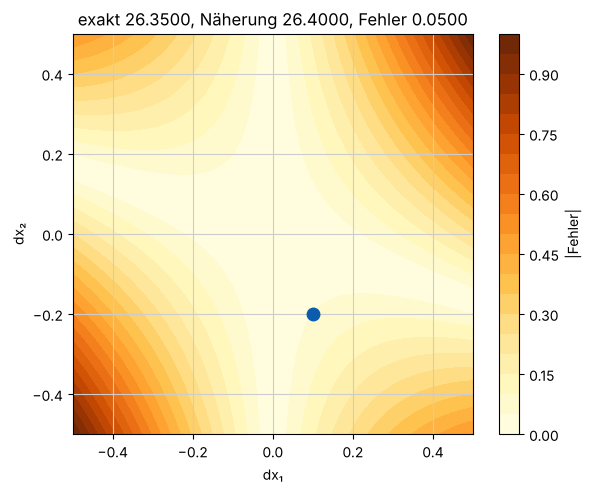

In [5]:
f264n = sp.lambdify((x1, x2), f264, 'numpy')


def zeige_naeherung(dx1=0.1, dx2=-0.2):
    D1, D2 = np.meshgrid(np.linspace(-0.5, 0.5, 201), np.linspace(-0.5, 0.5, 201))
    fehler = np.abs(f264n(3 + D1, 2 + D2) - (27 + 12*D1 + 9*D2))
    fig, ax = plt.subplots(figsize=(6.8, 5.2))
    cf = ax.contourf(D1, D2, fehler, levels=np.linspace(0, 1, 21), cmap='YlOrBr')
    plt.colorbar(cf, ax=ax, label='|Fehler|')
    ax.plot(dx1, dx2, 'o', color=BLAU, markersize=9)
    ex, nae = f264n(3 + dx1, 2 + dx2), 27 + 12*dx1 + 9*dx2
    ax.set(xlabel='dx₁', ylabel='dx₂', aspect='equal',
           title=f'exakt {ex:.4f}, Näherung {nae:.4f}, Fehler {abs(ex - nae):.4f}')
    plt.show()


d1_r = widgets.FloatSlider(value=0.1, min=-0.5, max=0.5, step=0.05, description='dx₁', continuous_update=False)
d2_r = widgets.FloatSlider(value=-0.2, min=-0.5, max=0.5, step=0.05, description='dx₂', continuous_update=False)
display(widgets.HBox([d1_r, d2_r]), widgets.interactive_output(zeige_naeherung, {'dx1': d1_r, 'dx2': d2_r}))

# Statische Vorschau für GitHub.
zeige_naeherung()

## 5. Anwendung: Fehlerfortpflanzung

Messgrößen sind fehlerbehaftet. Das totale Differential schätzt ab, wie sich Messfehler $\Delta x_i$ auf ein berechnetes Ergebnis $f(x_1,\dots,x_m)$ auswirken (**lineare Fehlerfortpflanzung**, Größtfehler):
$$|\Delta f|\lesssim\left|\frac{\partial f}{\partial x_1}\right|\,|\Delta x_1| + \dots + \left|\frac{\partial f}{\partial x_m}\right|\,|\Delta x_m|.$$

**Beispiel:** Ein zylindrischer Tank hat den gemessenen Radius $r = 2\,\text{m}\pm 0.01\,\text{m}$ und die Höhe $h = 5\,\text{m}\pm 0.02\,\text{m}$. Volumen $V = \pi r^2h$:
$$dV = 2\pi rh\,dr + \pi r^2\,dh\ \Rightarrow\ |\Delta V|\lesssim 2\pi\cdot 2\cdot 5\cdot 0.01 + \pi\cdot 4\cdot 0.02 = 0.28\pi\approx 0.88\,\text{m}^3.$$
Der relative Fehler ist $\frac{|\Delta V|}{V}\lesssim 2\frac{|\Delta r|}{r} + \frac{|\Delta h|}{h} = 1.4\,\%$: Der Radius geht doppelt ein, weil er quadriert wird. Eine Monte-Carlo-Simulation bestätigt die Größenordnung.

V = 62.83185307179586 m³,  Größtfehler |ΔV| ≈ 0.8796459430051421 m³ = 7*pi/25
relativer Fehler ≈ 1.4000000000000001 %


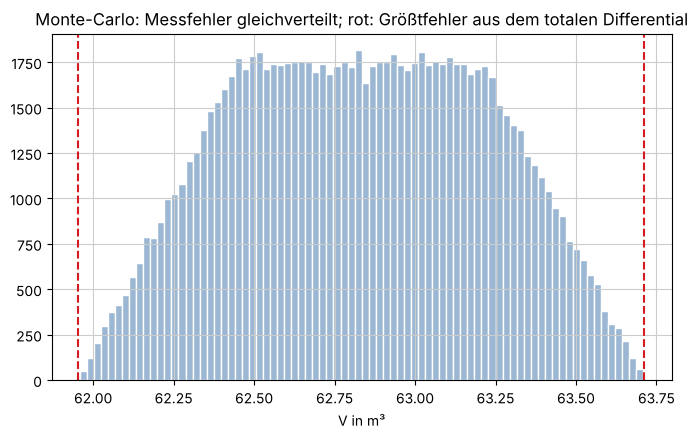

größte simulierte Abweichung: 0.8779183812581692 m³


In [6]:
r_, h_, dr_, dh_ = sp.symbols('r h dr dh', positive=True)
V = sp.pi*r_**2*h_
dV = sp.Abs(sp.diff(V, r_))*dr_ + sp.Abs(sp.diff(V, h_))*dh_
werte = {r_: 2, h_: 5, dr_: sp.Rational(1, 100), dh_: sp.Rational(2, 100)}
print('V =', float(V.subs(werte)), 'm³,  Größtfehler |ΔV| ≈', float(dV.subs(werte)), 'm³ =', sp.nsimplify(dV.subs(werte)))
print('relativer Fehler ≈', float((dV/V).subs(werte))*100, '%')

rng = np.random.default_rng(1)
r_s = rng.uniform(2 - 0.01, 2 + 0.01, 100_000); h_s = rng.uniform(5 - 0.02, 5 + 0.02, 100_000)
V_s = np.pi*r_s**2*h_s
plt.hist(V_s, bins=80, color='#9bb7d4', edgecolor='white')
for s in (-1, 1):
    plt.axvline(float(V.subs(werte)) + s*float(dV.subs(werte)), color=ROT, linestyle='--')
plt.xlabel('V in m³'); plt.title('Monte-Carlo: Messfehler gleichverteilt; rot: Größtfehler aus dem totalen Differential')
plt.show()
print('größte simulierte Abweichung:', np.max(np.abs(V_s - float(V.subs(werte)))), 'm³')